In [1]:
from anemone.experiment import *
from anemone.forwards import ForwardFD, ForwardFD2
import matplotlib.pyplot as plt
import numpy as np
from anemone import constants as c

In [2]:
tx = Loop([0, 1000], [0,0], [0,0])
rx = Receiver(x=100, y=100)

# tx = Loop.square(25)
# rx = Receiver()

#frq = torch.arange(1,51)*2000
frq = torch.logspace(-2, 5, 51)
fwr = ForwardFD(tx, rx, frq)
fwr2 = ForwardFD2(tx, rx, frq)

c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [3]:
rxs = Receiver(x = [0, 100, 150, 200], y=5)
rxs.xyz.shape

torch.Size([4, 3])

In [4]:
rxs = Receiver(x = [0, 100, 200], y=[5, 10])
rxs.xyz.shape

torch.Size([6, 3])

In [4]:
fwr = ForwardFD(tx, rxs, frq)
fwr2 = ForwardFD2(tx, rxs, frq)

In [5]:
sigma = 1/torch.tensor([40, 200, 80])
thick = torch.tensor([30, 30])

# sigma = torch.ones(2)
# thick = torch.ones(1)*30

hz1 = fwr(sigma, thick)
hz2 = fwr2(sigma, thick)

c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:142: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  R = torch.tensor(R, dtype=torch.float64)


In [6]:
hz1.shape

torch.Size([4, 51])

In [51]:
#tx = Loop([0, 1000], [0,0], [0,0])
tx = Loop.square(40)
rx = Receiver(x=4.9, y = torch.logspace(0, 2, 31))

# tx = Loop.square(25)
# rx = Receiver()
frq = torch.tensor([20000, 2001])

fwr = ForwardFD(tx, rx, frq)
fwr2 = ForwardFD2(tx, rx, frq)

In [52]:
sigma = 1/torch.tensor([40, 200, 80])
thick = torch.tensor([30, 30])

hz1 = fwr(sigma, thick)
hz2 = fwr2(sigma, thick).T

In [46]:
from time import perf_counter
bt = perf_counter()
hz1 = fwr(sigma, thick)
et = perf_counter()
print(f'time for ForwardFD: {1e3*(et-bt):1.1f}')

time for ForwardFD: 200.9


In [47]:
from time import perf_counter
bt = perf_counter()
hz2 = fwr2(sigma, thick)
et = perf_counter()
print(f'time for ForwardFD: {1e3*(et-bt):1.1f}')

time for ForwardFD: 12.7


In [48]:
%%timeit
hz2 = fwr2(sigma, thick).T

10.7 ms ± 997 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


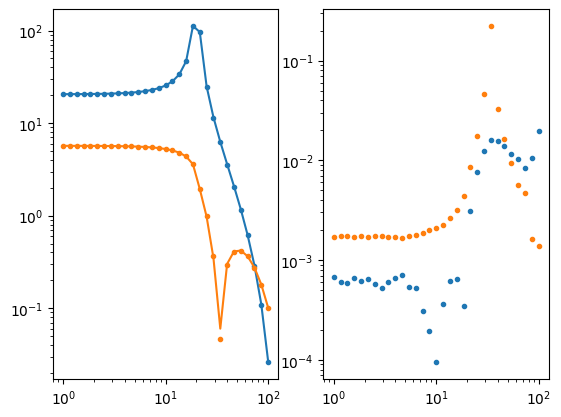

In [53]:
fig,axs = plt.subplots(1,2)
axs[0].loglog(rx.y.numpy(), np.abs(1e3*hz1.numpy()[...,0].real/c.mu0), label='reg')
axs[0].loglog(rx.y.numpy(), np.abs(1e3*hz2.numpy()[...,0].real/c.mu0), 'C0.', label='reg')
axs[0].loglog(rx.y.numpy(), np.abs(1e3*hz1.numpy()[...,0].imag/c.mu0), label='imag')
axs[0].loglog(rx.y.numpy(), np.abs(1e3*hz2.numpy()[...,0].imag/c.mu0), 'C1.', label='imag')

axs[1].loglog(rx.y.numpy(), np.abs(hz2.numpy()[...,0].real-hz1.numpy()[...,0].real)/np.abs(hz1.numpy()[...,0].real), '.', label='reg')
axs[1].loglog(rx.y.numpy(), np.abs(hz2.numpy()[...,0].imag-hz1.numpy()[...,0].imag)/np.abs(hz1.numpy()[...,0].imag), '.', label='imag')

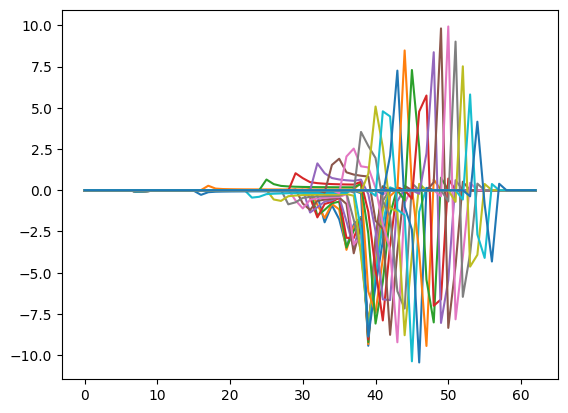

In [19]:
plt.figure()
plt.plot(fwr2.sofr.real.squeeze().T)

In [20]:
R = np.logspace(0, 2, 32)

In [21]:
dRnum = np.gradient(R)

dR = R*np.log(10)*(np.log10(R.max())-np.log10(R.min()))/(len(R))

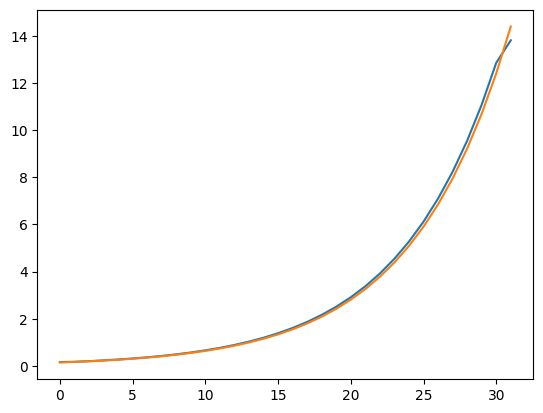

In [22]:
plt.figure()
plt.plot(dRnum)
plt.plot(dR)